## **Statistical Validation**
**Statistical Test** :

A mathematical tool that helps you figure out if a pattern or difference in your data is real or just a random fluke.

**P-Value**:

A number that tells you how likely it is that you test results happen purely by random chance.

**Small P-Value**: difficult to explaining result using chance alone 

**Large P-Value**:result can occur reasonably by chance.

**Hypothesis**: 2 statements:

   1.H(0)-null :No real effect

   2.H(1)-alternative: Real effect

Example:

H(0): The toss_winner wins 50% of decisive matches and H(1):The toss_winner win rate is not 50%.

**Alpha(α)**:
Alpha is the cut off value we choose before doing the test we use it to design whether the P-value is small enough to reject the H(0).

**alpha(α) =0.05**

P < 0.05 - Reject H(0) (result statistically significant)

In [130]:
%pip install scipy statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [131]:
from scipy import stats
import statsmodels.stats.proportion as smp

In [132]:
import pandas as pd
import sqlite3
con = sqlite3.connect("C:/Users/fathi/Downloads/ipl sem 3/IPL-Cricket-Analyticss/data/raw/ipl.db")
def q(sql):
    return pd.read_sql(sql,con)

In [133]:
toss_test=q("""
SELECT
      COUNT(*) AS n,
      SUM(CASE
          WHEN toss_winner=match_winner THEN 1
          ELSE 0 END) AS k
FROM matches_clean
WHERE result='win';
""")
toss_test

,n,k
0,1187,613


In [134]:
result=stats.binomtest(
    k=613,
    n=1187,
    p=0.5)
result

BinomTestResult(k=613, n=1187, alternative='two-sided', statistic=0.5164279696714406, pvalue=0.2700389712415702)

In [135]:
ci_low,ci_high=smp.proportion_confint(
    count=613,
    nobs=1187,
    alpha=0.05,
)

ci_low,ci_high

(0.48799919141387527, 0.5448567479290058)

Confidence Interval

Gives us a range of believable values for the underlying value based on sample data.

In our IPL data, the toss-winner is 51.64% of decisive matches. There is our observed proportion (point estimate). Instead of depending only on the single value, we calculate a confidence interval to show uncertainty in our estimate.

T TEST

In [136]:
toss_decision_table = q("""

SELECT

    CASE
        WHEN toss_decision = 'bat' THEN 'bat'
        WHEN toss_decision = 'field' THEN 'field'
        ELSE 'unknown'
    END AS toss_decision,

    SUM(CASE
        WHEN toss_winner = match_winner THEN 1
        ELSE 0
    END) AS toss_winner_won,

    SUM(CASE
        WHEN toss_winner != match_winner THEN 1
        ELSE 0
    END) AS toss_winner_didnt_win,

    COUNT(*) AS total_matches

FROM matches_clean

WHERE result = 'win'

GROUP BY toss_decision

ORDER BY toss_decision;

""")

In [137]:
toss_decision_table

,toss_decision,toss_winner_won,toss_winner_didnt_win,total_matches
0,bat,184,218,402
1,field,429,356,785


In [138]:
table=[[184,218],
      [429,356]
]

In [139]:
chi2,p,dof,expected=stats.chi2_contingency(table)
chi2,p,dof

(np.float64(8.04007460861096), np.float64(0.004575365240151297), 1)

In [140]:
q("""
SELECT 
     COUNT(CASE WHEN win_by_runs IS NOT NULL THEN 1 END) AS run_wins,
     COUNT(CASE WHEN win_by_wickets IS NOT NULL THEN 1 END) AS wicket_wins
FROM matches_clean
WHERE result='win';
""")


,run_wins,wicket_wins
0,546,641


In [141]:
q("""
SELECT
      CASE
      WHEN match_winner=innings1_batting_team
         THEN 'Defended'
      ELSE 'Chased Down'
      END AS outcome,
      COUNT(*) AS n,
      ROUND(AVG(first_innings_total),1) AS avg_first_innings_total
FROM v_match_totals
WHERE result='win'
AND first_innings_total IS NOT NULL
GROUP BY outcome;
""")

,outcome,n,avg_first_innings_total
0,Chased Down,647,155.5
1,Defended,540,183.3


In [142]:
defended=q("""
SELECT first_innings_total
FROM v_match_totals
WHERE result='win'
AND first_innings_total IS NOT NULL
AND match_winner=innings1_batting_team;
""")['first_innings_total']

chased=q("""
SELECT first_innings_total
FROM v_match_totals
WHERE result='win'
AND first_innings_total IS NOT NULL
AND match_winner!=innings1_batting_team;
""")['first_innings_total']
len(defended),len(chased),defended.mean(),chased.mean()

(540, 647, np.float64(183.34074074074073), np.float64(155.53786707882534))

In [143]:
t_stat,p_value=stats.ttest_ind(
    defended,
    chased,
    equal_var=False)
t_stat,p_value


(np.float64(15.730238965353694), np.float64(1.17272268263676e-50))

REJECT H0(NULL HYPOTHEIS)-There is statiscally significant evidence that the average first innings total differs between defended and chased down matches 

In [144]:
with open ("../sql/02_category_cleaning.sql","r") as file:
    sql_script=file.read()
con.executescript(sql_script)
con.commit()


In [145]:
q("""
SELECT
      bowler_type,
      COUNT(*) AS n
FROM v_deliveries_category_clean
GROUP BY bowler_type_clean
ORDER BY bowler_type_clean;""")

,bowler_type,n
0,,347
1,Left arm Fast,3727
2,Left arm Fast medium,15376
3,Left arm Medium,8778
4,Left arm Medium fast,13495
5,Left arm Wrist spin,4279
6,Legbreak,13893
7,Legbreak Googly,22670
8,Right arm Fast,42126
9,Right arm Fast medium,31227


In [146]:
bowler_economy = q("""
SELECT bowler, bowler_type_clean,
    SUM(
        total_runs
        - COALESCE(bye_runs, 0)
        - COALESCE(leg_bye_runs, 0)
        - COALESCE(penalty_runs, 0)
    ) AS runs_conceded,
    
    SUM(
        CASE
            WHEN is_wide_ball = 0
            AND is_no_ball = 0
            THEN 1 ELSE 0
        END
    ) AS legal_balls

FROM v_deliveries_category_clean

WHERE bowler_type_clean IS NOT NULL
    AND is_super_over = 0

GROUP BY bowler, bowler_type_clean;
""")

bowler_economy.head()

,bowler,bowler_type_clean,runs_conceded,legal_balls
0,A Ashish Reddy,Right arm Medium,396,262
1,A Badoni,Right arm Offbreak,63,41
2,A Chandila,Right arm Offbreak,242,234
3,A Choudhary,Left arm Medium,144,101
4,A Dananjaya,"Right arm Offbreak, Legbreak",47,24


In [147]:
bowler_economy['economy_rate']=(
    bowler_economy['runs_conceded']
    /bowler_economy['legal_balls']
    *6)
bowler_economy.head()

,bowler,bowler_type_clean,runs_conceded,legal_balls,economy_rate
0,A Ashish Reddy,Right arm Medium,396,262,9.068702
1,A Badoni,Right arm Offbreak,63,41,9.219512
2,A Chandila,Right arm Offbreak,242,234,6.205128
3,A Choudhary,Left arm Medium,144,101,8.554455
4,A Dananjaya,"Right arm Offbreak, Legbreak",47,24,11.750000


In [148]:
qualified_bowlers=bowler_economy[
    bowler_economy['legal_balls']>=200].copy()
len(qualified_bowlers)

277

In [149]:
def classify_bowler_type(x):
    x = str(x)

    # Spin style
    if ('spin' in x.lower()
        or 'legbreak' in x.lower()
        or 'offbreak' in x.lower()
        or 'orthodox' in x.lower()):
        return "Spin"

    # Pace styles
    elif 'fast medium' in x.lower():
        return "Medium-fast"
    elif 'medium fast' in x.lower():
        return "Medium-fast"
    elif 'fast' in x.lower():
        return "Fast"
    elif 'medium' in x.lower():
        return "Medium"

    return None


qualified_bowlers['group'] = qualified_bowlers['bowler_type_clean'].apply(
    classify_bowler_type
)

qualified_bowlers.groupby('group').size()

group
Fast           36
Medium         52
Medium-fast    96
Spin           93
dtype: int64

In [150]:
qualified_bowlers.groupby('group')['economy_rate'].mean().round(3)


group
Fast           8.647
Medium         8.752
Medium-fast    8.736
Spin           7.983
Name: economy_rate, dtype: float64

In [151]:
fast=qualified_bowlers.loc[
    qualified_bowlers['group']=='Fast','economy_rate']

medium=qualified_bowlers.loc[
    qualified_bowlers['group']=='Medium','economy_rate']

medium_fast=qualified_bowlers.loc[
    qualified_bowlers['group']=='Medium-fast','economy_rate']

spin=qualified_bowlers.loc[
    qualified_bowlers['group']=='Spin','economy_rate']

anova_result=stats.f_oneway(
    fast,medium,medium_fast,spin)
anova_result




F_onewayResult(statistic=np.float64(13.444563171677368), pvalue=np.float64(3.293037349980493e-08))

the four group annova found a statistically significant difference in economy rate among bowling types.group means suggest that spin bowlers drive this diffrence ,with a lower mean economy rate than the 3 pace group.

T test

In [152]:
qualified_bowlers['pace_spin']=qualified_bowlers['group'].apply(
    lambda x:'Spin' if x=='Spin' else 'Pace')
qualified_bowlers.groupby('pace_spin').size()

pace_spin
Pace    184
Spin     93
dtype: int64

H0-mean economy rate is the same for pace bowlers and spin bowlers   
H1-mean economy rate is the different for pace bowlers and spin bowlers

In [153]:
qualified_bowlers.groupby('pace_spin')['economy_rate'].agg(
    ['count','mean']).round(3)


,count,mean
pace_spin,,
Pace,184,8.723
Spin,93,7.983


T test

In [154]:
spin_group =qualified_bowlers.loc[
    qualified_bowlers['pace_spin'] == 'Spin',
    "economy_rate"
]

pace_group = qualified_bowlers.loc[
    qualified_bowlers['pace_spin'] == 'Pace',
    "economy_rate"
]

pace_spin_test =stats.ttest_ind(
    spin_group,
    pace_group,
    equal_var= False
)

pace_spin_test

TtestResult(statistic=np.float64(-6.756516082693141), pvalue=np.float64(1.2614457218871515e-10), df=np.float64(218.7300288385927))

cohens d

In [155]:
import numpy as np
n_spin=len(spin_group)
n_pace=len(pace_group)
pooled_sd=np.sqrt(
    ((n_spin - 1)*spin_group.var(ddof=1) + (n_pace - 1)*pace_group.var(ddof=1))/(n_spin + n_pace - 2)
)
cohens_d=(
    pace_group.mean() - spin_group.mean()
)/pooled_sd
pooled_sd,cohens_d


(np.float64(0.9169422212292374), np.float64(0.8073713639431691))

correlation-  it measures how strongly to numerical variable move together.

r -correlation coefficient

* r= 1 perfect positive relationship

* r= 0 no linear relationship

* r=-1 perfect negative relationship

question - Has ipl scored increased across seasons?

In [156]:
match_runs = q("""
SELECT match_id, SUM(total_runs) AS combined_runs
FROM deliveries
WHERE is_super_over = 0
GROUP BY match_id
ORDER BY match_id;
""")
match_runs.head()

,match_id,combined_runs
0,335982,304
1,335983,447
2,335984,261
3,335985,331
4,335986,222


In [157]:
season_scoring = q('''
WITH match_runs AS (
    SELECT
        match_id,
        SUM(total_runs) AS combined_runs
    FROM deliveries
    WHERE is_super_over = 0
    GROUP BY match_id
)
SELECT
    m.season_year,
    AVG(r.combined_runs) AS avg_combined_runs
FROM matches_clean AS m
JOIN match_runs AS r
    ON m.match_id = r.match_id
GROUP BY m.season_year
ORDER BY m.season_year;
''')

season_scoring

,season_year,avg_combined_runs
0,2008,309.258621
1,2009,286.315789
2,2010,314.400000
3,2011,289.780822
4,2012,303.418919
5,2013,296.592105
6,2014,315.150000
7,2015,310.711864
8,2016,314.366667
9,2017,318.118644


pearson correlation- it is a number btw -1 and +1 that tells you how strongly two things are related

In [158]:
r,p_value = stats.pearsonr(
    season_scoring["season_year"],
    season_scoring["avg_combined_runs"]
)
r,p_value

(np.float64(0.8610043249540036), np.float64(2.2182879043152464e-06))

as the ipl season progress, the average combined runs per match generally increase.
the correlation is strong and positive

In [159]:
r_squared = r ** 2
r_squared

np.float64(0.7413284475894995)

r2= coefficient of determination

about 74.1% of variation in average season scoring is associated with the linear trend across season years

CONFOUND

Another factor that could help explain the relationship we see 

ALL though IPL scoring increase across seasons ,those relationship may also be influenced by rule changes,boundaries sizes or pitch preparation,battinng technology or venue mix 

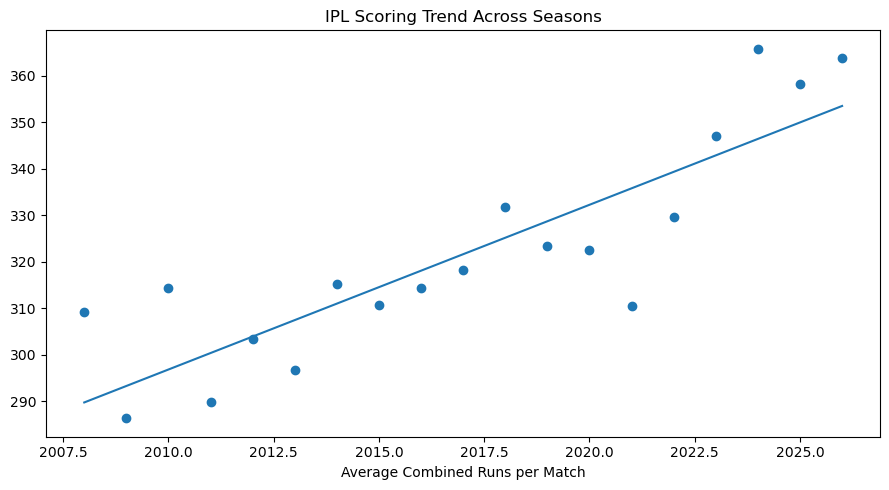

In [160]:
import matplotlib.pyplot as plt
import numpy as np

x=season_scoring['season_year']
y=season_scoring['avg_combined_runs']
m,b=np.polyfit(x,y,1)
plt.figure(figsize=(9,5))
plt.scatter(x,y)
plt.plot(x,m*x+b)
plt.xlabel("Season Year")
plt.xlabel("Average Combined Runs per Match")
plt.title("IPL Scoring Trend Across Seasons")
plt.tight_layout()
plt.show()

In [161]:
venue_sample=q("""SELECT venue_clean,COUNT(*) AS n_matches
FROM matches_clean
WHERE result='win'
GROUP BY venue_clean
ORDER BY n_matches DESC
LIMIT 8;""")
venue_sample

,venue_clean,n_matches
0,Wankhede Stadium,129
1,Eden Gardens,102
2,M Chinnaswamy Stadium,100
3,MA Chidambaram Stadium,93
4,Rajiv Gandhi International Stadium,85
5,Sawai Mansingh Stadium,66
6,Feroz Shah Kotla,59
7,Dubai International Cricket Stadium,43


In [162]:
venue_chase = q("""
WITH top_venues AS (
    SELECT venue_clean
    FROM matches_clean
    GROUP BY venue_clean
    ORDER BY COUNT(*) DESC
    LIMIT 8
)
SELECT
    m.venue_clean,
    SUM(CASE WHEN m.win_by_wickets > 0 THEN 1 ELSE 0
    END) AS chase_won,
    SUM(CASE WHEN m.win_by_runs > 0 THEN 1 ELSE 0
    END) AS chase_not_won,
    COUNT(*) AS total_matches
FROM matches_clean AS m
JOIN top_venues AS t
    ON m.venue_clean = t.venue_clean
WHERE m.result = 'win'
GROUP BY m.venue_clean
ORDER BY total_matches DESC;
""")

venue_chase

,venue_clean,chase_won,chase_not_won,total_matches
0,Wankhede Stadium,71,58,129
1,Eden Gardens,57,45,102
2,M Chinnaswamy Stadium,56,44,100
3,MA Chidambaram Stadium,42,51,93
4,Rajiv Gandhi International Stadium,46,39,85
5,Sawai Mansingh Stadium,43,23,66
6,Feroz Shah Kotla,31,28,59
7,Dubai International Cricket Stadium,22,21,43


In [163]:
venue_table=venue_chase[
    ['chase_won','chase_not_won']].to_numpy()
venue_table

array([[71, 58],
       [57, 45],
       [56, 44],
       [42, 51],
       [46, 39],
       [43, 23],
       [31, 28],
       [22, 21]])

h0-

In [164]:
chi2,p,dof,expected=stats.chi2_contingency(venue_table)
chi2,p,dof

(np.float64(6.755188260729701), np.float64(0.45480700216342773), 7)

H0-Failed to reject(Null Hypothesis)

DOES NT A BIG Sample make everything significant 
h0-no diffrence mean runs between poer play  and middle overs
h1-there is a diffrence  mean between power play and middle overs 

In [165]:
q("""
SELECT
    CASE WHEN over_number BETWEEN 0 AND 5 THEN 'Powerplay'
        WHEN over_number BETWEEN 6 AND 14 THEN 'Middle'END AS phase,
    COUNT(*) AS balls
FROM deliveries
WHERE is_super_over = 0
AND over_number BETWEEN 0 AND 14
GROUP BY phase;
""")

,phase,balls
0,Middle,132173
1,Powerplay,90390


In [166]:
phase_rates=q("""
SELECT
    CASE
        WHEN over_number BETWEEN 0 AND 5 THEN 'Powerplay'
        WHEN over_number BETWEEN 6 AND 14 THEN 'Middle Overs'
    END AS phase,
    SUM(total_runs) AS total_runs,
    SUM( CASE WHEN is_wide_ball = 0 AND is_no_ball = 0 THEN 1 ELSE 0 END) AS legal_balls,
    ROUND(6.0 * SUM(total_runs) /SUM(CASE WHEN is_wide_ball = 0 AND is_no_ball = 0 THEN 1 ELSE 0 END), 2) AS runs_per_over
FROM deliveries
WHERE is_super_over = 0
  AND over_number BETWEEN 0 AND 14
GROUP BY phase
ORDER BY MIN(over_number);
""")
phase_rates

,phase,total_runs,legal_balls,runs_per_over
0,Powerplay,116397,86921,8.03
1,Middle Overs,169160,128191,7.92


In [167]:
phase_test_data=q("""
SELECT
    CASE
        WHEN over_number BETWEEN 0 AND 5 THEN 'Powerplay'
        WHEN over_number BETWEEN 6 AND 14 THEN 'Middle Overs'
    END AS phase,
    total_runs
FROM deliveries
WHERE is_super_over = 0
  AND over_number BETWEEN 0 AND 14;
""")
phase_test_data.groupby('phase').agg(
    n=('total_runs','count'),
    mean_runs=('total_runs','mean'))

,n,mean_runs
phase,,
Middle Overs,132173,1.279838
Powerplay,90390,1.287720


In [171]:
powerplay = phase_test_data.loc[
    phase_test_data['phase'] == 'Powerplay','total_runs']

middle_overs = phase_test_data.loc[
    phase_test_data['phase'] == 'Middle Overs','total_runs']

phase_ttest = stats.ttest_ind(
    powerplay,
    middle_overs,
    equal_var=False
)

phase_ttest

TtestResult(statistic=np.float64(1.1205967786430735), pvalue=np.float64(0.26246102785681247), df=np.float64(180490.54605896366))

There is insufficient evidence to suggest that the mean runs per delivery during the power play and middle overs are statistically significantly different 

In [174]:
n_powerplay = len(powerplay)
n_middle = len(middle_overs)

pooled_sd = np.sqrt(
    (
        (n_powerplay - 1) * powerplay.var(ddof=1)
        + (n_middle - 1) * middle_overs.var(ddof=1)
    ) / (n_powerplay + n_middle - 2)
)

cohens_d = (
    powerplay.mean() - middle_overs.mean()
) / pooled_sd

pooled_sd, cohens_d

(np.float64(1.5980425254215087), np.float64(0.004932341936603954))

we failed to reject null hypothesis .the difference between power play and middle over scoring is not statiscally significant and the effect size is approximately 0 

H0-left handed and right handed qualified batters have the same mean strike rate      

H1-left handed and right handed qualified batters have the different mean strike rate 

In [175]:
batter_stats=q("""
SELECT
    CASE
        WHEN over_number BETWEEN 0 AND 5 THEN 'batter'
        WHEN over_number BETWEEN 6 AND 14 THEN 'batsman_type'
    END AS phase,
    SUM(total_runs) AS batsman_type,
    SUM( CASE WHEN is_wide_ball = 0 AND is_no_ball = 0 THEN 1 ELSE 0 END) AS runs,
    ROUND(6.0 * SUM(total_runs) /SUM(CASE WHEN is_wide_ball = 0 AND is_no_ball = 0 THEN 1 ELSE 0 END), 2) AS balls_faced
FROM deliveries
WHERE is_super_over = 0
  AND over_number BETWEEN 0 AND 14
GROUP BY phase
ORDER BY MIN(over_number);
""")
batter_stats.head()

,phase,batsman_type,runs,balls_faced
0,batter,116397,86921,8.03
1,batsman_type,169160,128191,7.92


In [177]:
batter_stats=q("""
SELECT batter,batsman_type,
SUM(batter_runs) AS runs,
SUM(CASE WHEN is_wide_ball=0
AND is_no_ball=0 THEN 1 ELSE 0 END) AS balls_faced
FROM deliveries
WHERE is_super_over=0
GROUP BY batter,batsman_type;
""")
batter_stats.head()

,batter,batsman_type,runs,balls_faced
0,A Ashish Reddy,Right hand Bat,280,193
1,A Badoni,Right hand Bat,1135,815
2,A Chandila,Right hand Bat,4,7
3,A Chopra,Right hand Bat,53,71
4,A Choudhary,Right hand Bat,25,20


In [179]:
qualified_batters=batter_stats[batter_stats['balls_faced']>=300].copy()
qualified_batters['strike_rate']=(qualified_batters['runs']/qualified_batters['balls_faced']*100)

qualified_batters.groupby('batsman_type').agg(
    n=('batter','count'),
    mean_strike_rate=('strike_rate','mean')
)
                                  

,n,mean_strike_rate
batsman_type,,
Left hand Bat,63,137.504943
Right hand Bat,118,134.504815


In [186]:
left=qualified_batters.loc[qualified_batters['batsman_type']=='Left hand Bat','strike_rate']

right=qualified_batters.loc[qualified_batters['batsman_type']=='Right hand Bat','strike_rate']

handedness_test=stats.ttest_ind(left,right,equal_var=False)
handedness_test

TtestResult(statistic=np.float64(1.1524767028583889), pvalue=np.float64(0.2512365800176446), df=np.float64(130.21598081265117))

In [187]:
n_left=len(left)
n_right=len(right)
pooled_sd=np.sqrt(((n_left -1) * left.var(ddof=1) +(n_right -1) * right.var(ddof=1))/(n_left + n_right -2))
cohens_d=(
    left.mean()-right.mean()
)/pooled_sd
pooled_sd,cohens_d

(np.float64(16.84341925034525), np.float64(0.17811874232505945))

In [189]:
from pathlib import Path
report_path=Path('../reports/statistical_report.md')
report_path.touch(exist_ok=True)
print(report_path)

..\reports\statistical_report.md
